In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pharmaceutical Data Analysis")
print("Python libraries loaded successfully!")


Pharmaceutical Data Analysis
Python libraries loaded successfully!


In [8]:
from pathlib import Path

# Project folder
project_folder = Path.cwd()

# Excel file
file_path = project_folder / "Pharma_Analytics_Cleaned.xlsx"

# Read Excel dataset
df = pd.read_excel(
    file_path,
    sheet_name="pharma_sales_inventory_6000_row"
)

# Remove temporary helper column
df = df.drop(columns=["Duplicate_Check"], errors="ignore")

print("Dataset imported successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset imported successfully!
Dataset Shape: (6000, 16)


,order_id,order_date,product_id,product_name,category,manufacturer_id,manufacturer,batch_no,region,units_sold,unit_price,unit_cost,stock_on_hand,reorder_level,expiry_date,quality_status
0,ORD00001,2025-10-10,P002,Amoxicillin 250mg,Antibiotic,M002,NovaMed Labs,B5737,Tirunelveli,331.0,155.68,107.30,526.0,150.0,2026-07-13,Passed
1,ORD00002,2025-10-14,P009,ORS Sachet,Hydration,M005,BioCare Ltd,B8033,Trichy,261.0,85.47,50.53,153.0,145.0,2028-11-12,Passed
2,ORD00003,2025-06-11,P007,Vitamin C 500mg,Supplement,M005,BioCare Ltd,B3490,Trichy,231.0,103.39,51.61,272.0,314.0,2028-03-31,Passed
3,ORD00004,2025-05-10,P009,ORS Sachet,Hydration,M005,BioCare Ltd,B4274,Madurai,43.0,161.62,115.32,1164.0,289.0,2026-05-23,Passed
4,ORD00005,2025-02-26,P007,Vitamin C 500mg,Supplement,M005,BioCare Ltd,B9148,Madurai,374.0,136.10,104.83,819.0,202.0,2026-07-23,Passed


In [9]:
# Check the actual Excel file location
print("Excel file location:")
print(file_path.resolve())

print("\nFile exists:")
print(file_path.exists())

# Check available sheets
excel = pd.ExcelFile(file_path)

print("\nSheet names:")
print(excel.sheet_names)

# Check duplicate Order IDs
print("\nDuplicate Order IDs:")
print(df["order_id"].duplicated().sum())

# Check dataset dimensions
print("\nDataset shape:")
print(df.shape)

Excel file location:
C:\Users\ELCOT\Desktop\Pharmaceutical_Data_Analyst_Project\Pharma_Analytics_Cleaned.xlsx

File exists:
True

Sheet names:
['pharma_sales_inventory_6000_row', 'Data_audit.']

Duplicate Order IDs:
11

Dataset shape:
(6000, 16)


In [10]:
df["order_id"].duplicated().sum()

np.int64(11)

In [11]:
# Find all duplicate Order IDs
duplicate_records = df[
    df["order_id"].duplicated(keep=False)
].sort_values("order_id")

print("Duplicate records:")
display(duplicate_records)

print("Total duplicate rows:", len(duplicate_records))

print("Unique duplicate Order IDs:")
print(duplicate_records["order_id"].nunique())

Duplicate records:


,order_id,order_date,product_id,product_name,category,manufacturer_id,manufacturer,batch_no,region,units_sold,unit_price,unit_cost,stock_on_hand,reorder_level,expiry_date,quality_status
5988,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
5989,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
5990,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
5991,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
5992,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
5993,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
5994,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
5995,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
5996,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
5997,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN


Total duplicate rows: 12
Unique duplicate Order IDs:
0


In [12]:
# Remove rows with missing Order ID
df_clean = df.dropna(subset=["order_id"]).copy()

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))

print("Missing Order IDs:",
      df_clean["order_id"].isnull().sum())

print("Duplicate Order IDs:",
      df_clean["order_id"].duplicated().sum())

Original records: 6000
Cleaned records: 5988
Missing Order IDs: 0
Duplicate Order IDs: 0


In [13]:
print("Missing stock values:")

print(df_clean["stock_on_hand"].isnull().sum())

Missing stock values:
20


In [14]:
# Convert numerical columns into numeric format

numeric_columns = [
    "units_sold",
    "unit_price",
    "unit_cost",
    "stock_on_hand",
    "reorder_level"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

print("Numerical columns prepared successfully!")

display(df_clean[numeric_columns].head())

Numerical columns prepared successfully!


,units_sold,unit_price,unit_cost,stock_on_hand,reorder_level
0,331.0,155.68,107.30,526.0,150.0
1,261.0,85.47,50.53,153.0,145.0
2,231.0,103.39,51.61,272.0,314.0
3,43.0,161.62,115.32,1164.0,289.0
4,374.0,136.10,104.83,819.0,202.0


In [15]:
# Calculate total sales revenue
df_clean["revenue"] = (
    df_clean["units_sold"] * df_clean["unit_price"]
)

# Calculate total product cost
df_clean["total_cost"] = (
    df_clean["units_sold"] * df_clean["unit_cost"]
)

# Calculate profit
df_clean["profit"] = (
    df_clean["revenue"] - df_clean["total_cost"]
)

# Calculate profit margin
df_clean["profit_margin"] = np.where(
    df_clean["revenue"] != 0,
    (df_clean["profit"] / df_clean["revenue"]) * 100,
    0
)

print("Business calculations completed!")

display(
    df_clean[
        ["product_name", "units_sold", "revenue",
         "total_cost", "profit", "profit_margin"]
    ].head(10)
)

Business calculations completed!


,product_name,units_sold,revenue,total_cost,profit,profit_margin
0,Amoxicillin 250mg,331.0,51530.08,35516.30,16013.78,31.076567
1,ORS Sachet,261.0,22307.67,13188.33,9119.34,40.879841
2,Vitamin C 500mg,231.0,23883.09,11921.91,11961.18,50.082213
3,ORS Sachet,43.0,6949.66,4958.76,1990.90,28.647445
4,Vitamin C 500mg,374.0,50901.40,39206.42,11694.98,22.975753
5,Atorvastatin 10mg,237.0,21287.34,11667.51,9619.83,45.190381
6,Amlodipine 5mg,57.0,8615.55,6215.28,2400.27,27.859742
7,Amlodipine 5mg,418.0,3874.86,2775.52,1099.34,28.371090
8,Vitamin C 500mg,258.0,8268.90,4254.42,4014.48,48.549142
9,Paracetamol 500mg,292.0,30140.24,19523.12,10617.12,35.225731


In [16]:
total_units = df_clean["units_sold"].sum()

total_revenue = df_clean["revenue"].sum()

total_cost = df_clean["total_cost"].sum()

total_profit = df_clean["profit"].sum()

overall_margin = (
    total_profit / total_revenue * 100
    if total_revenue != 0 else 0
)

print("PHARMACEUTICAL BUSINESS REPORT")
print("--------------------------------")
print("Total Units Sold:", total_units)
print("Total Revenue: ₹", round(total_revenue, 2))
print("Total Cost: ₹", round(total_cost, 2))
print("Total Profit: ₹", round(total_profit, 2))
print("Profit Margin:", round(overall_margin, 2), "%")

PHARMACEUTICAL BUSINESS REPORT
--------------------------------
Total Units Sold: 1528247.0
Total Revenue: ₹ 144501216.89
Total Cost: ₹ 90942844.0
Total Profit: ₹ 53558372.89
Profit Margin: 37.06 %


In [17]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Units Sold",
        "Total Revenue",
        "Total Cost",
        "Total Profit",
        "Profit Margin (%)"
    ],
    "Value": [
        total_units,
        round(total_revenue, 2),
        round(total_cost, 2),
        round(total_profit, 2),
        round(overall_margin, 2)
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Units Sold,1.528247e+06
1,Total Revenue,1.445012e+08
2,Total Cost,9.094284e+07
3,Total Profit,5.355837e+07
4,Profit Margin (%),3.706000e+01


In [18]:
product_sales = (
    df_clean.groupby("product_name")
    .agg(
        total_units=("units_sold", "sum"),
        total_revenue=("revenue", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

product_sales = product_sales.sort_values(
    by="total_units",
    ascending=False
)

top_10_products = product_sales.head(10)

display(top_10_products)

,product_name,total_units,total_revenue,total_profit
6,Metformin 500mg,136050.0,12445992.28,4641317.21
2,Atorvastatin 10mg,132186.0,12832084.82,4745878.56
1,Amoxicillin 250mg,129481.0,12244596.31,4526633.07
11,Vitamin C 500mg,128413.0,11936991.95,4423548.77
4,Cetirizine 10mg,128307.0,12343137.32,4508035.05
8,Omeprazole 20mg,127569.0,12307927.82,4565924.92
7,ORS Sachet,127484.0,11813482.55,4431780.21
10,Paracetamol 500mg,127470.0,12229710.92,4486037.28
5,Diclofenac 50mg,127359.0,12231622.21,4670800.65
9,Pantoprazole 40mg,123614.0,11062735.67,4088421.66


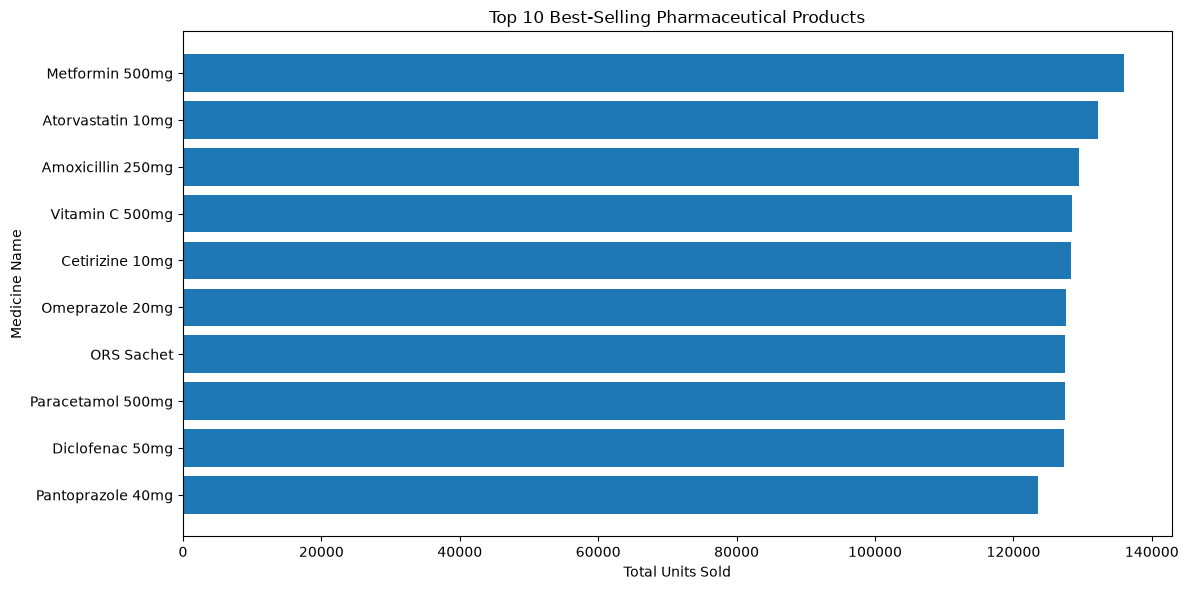

In [19]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_products["product_name"],
    top_10_products["total_units"]
)

plt.xlabel("Total Units Sold")
plt.ylabel("Medicine Name")
plt.title("Top 10 Best-Selling Pharmaceutical Products")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [20]:
manufacturer_sales = (
    df_clean.groupby("manufacturer")
    .agg(
        total_units=("units_sold", "sum"),
        total_revenue=("revenue", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

manufacturer_sales = manufacturer_sales.sort_values(
    by="total_revenue",
    ascending=False
)

display(manufacturer_sales.head(10))

,manufacturer,total_units,total_revenue,total_profit
4,NovaMed Labs,376783.0,35893056.32,13505488.70
0,Apex Pharma,387134.0,35738438.87,13215776.15
3,HealthBridge,259755.0,25140012.64,9311803.48
2,CureWell Pharma,248678.0,23979234.56,8669975.58
1,BioCare Ltd,255897.0,23750474.50,8855328.98


In [21]:
region_sales = (
    df_clean.groupby("region")
    .agg(
        total_revenue=("revenue", "sum"),
        total_profit=("profit", "sum"),
        total_units=("units_sold", "sum")
    )
    .reset_index()
)

region_sales = region_sales.sort_values(
    by="total_revenue",
    ascending=False
)

display(region_sales)

,region,total_revenue,total_profit,total_units
3,Salem,24974000.40,9193693.25,264180.0
2,Madurai,24508319.53,9076391.37,249644.0
5,Trichy,24417635.19,9129065.34,256794.0
0,Chennai,24292104.42,9119690.35,263311.0
4,Tirunelveli,24150912.24,8856164.06,257981.0
1,Coimbatore,22158245.11,8183368.52,236337.0


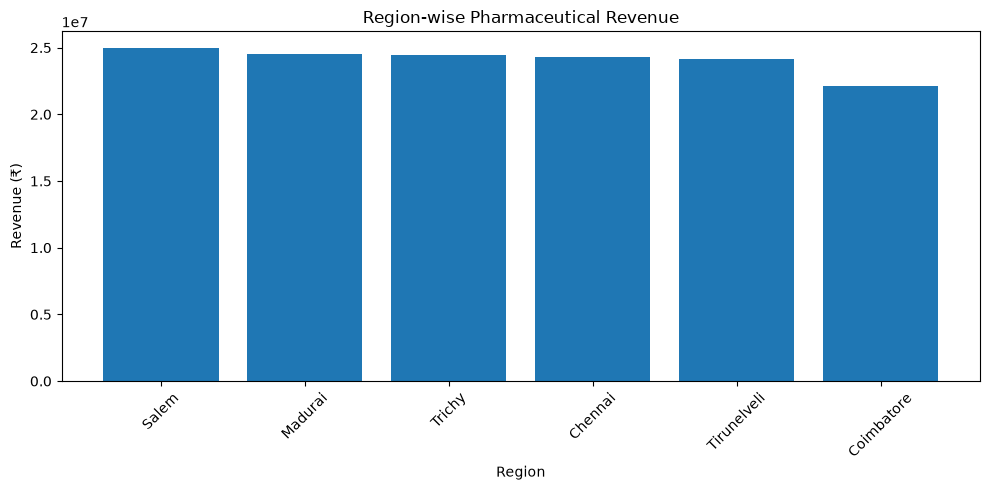

In [22]:
plt.figure(figsize=(10, 5))

plt.bar(
    region_sales["region"],
    region_sales["total_revenue"]
)

plt.title("Region-wise Pharmaceutical Revenue")
plt.xlabel("Region")
plt.ylabel("Revenue (₹)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


In [6]:
# Create regional sales summary

region_sales = (
    df_clean.groupby("region")
    .agg(
        total_revenue=("revenue", "sum"),
        total_profit=("profit", "sum"),
        total_units=("units_sold", "sum")
    )
    .reset_index()
)

# Sort highest revenue first
region_sales = region_sales.sort_values(
    by="total_revenue",
    ascending=False
)

# Display results
display(region_sales)

NameError: name 'df_clean' is not defined

In [3]:
print("df_clean exists:", "df_clean" in globals())

df_clean exists: False


In [4]:
# Remove empty Order ID rows
df_clean = df.dropna(subset=["order_id"]).copy()

# Remove duplicate Order IDs, if any
df_clean = df_clean.drop_duplicates(
    subset=["order_id"],
    keep="first"
).copy()

print("Cleaned dataset:", df_clean.shape)

NameError: name 'df' is not defined

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import FuncFormatter

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
project_folder = Path.cwd()

file_path = project_folder / "Pharma_Analytics_Cleaned.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="pharma_sales_inventory_6000_row"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (6000, 17)


In [9]:
# Display all column names
print("Columns:")
print(df.columns.tolist())

# Remove empty Order ID rows
df_clean = df.dropna(subset=["order_id"]).copy()

# Remove duplicate Order IDs
df_clean = df_clean.drop_duplicates(
    subset=["order_id"],
    keep="first"
).copy()

# Remove temporary helper column if present
df_clean = df_clean.drop(
    columns=["Duplicate_Check"],
    errors="ignore"
)

print("\nOriginal dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

print(
    "Missing Order IDs:",
    df_clean["order_id"].isna().sum()
)

print(
    "Duplicate Order IDs:",
    df_clean["order_id"].duplicated().sum()
)

Columns:
['order_id', 'order_date', 'product_id', 'product_name', 'category', 'manufacturer_id', 'manufacturer', 'batch_no', 'region', 'units_sold', 'unit_price', 'unit_cost', 'stock_on_hand', 'reorder_level', 'expiry_date', 'quality_status', 'Duplicate_Check']

Original dataset: (6000, 17)
Cleaned dataset: (5988, 16)
Missing Order IDs: 0
Duplicate Order IDs: 0


In [10]:
# Calculate Revenue
df_clean["revenue"] = (
    df_clean["units_sold"] * df_clean["unit_price"]
)

# Calculate Total Cost
df_clean["total_cost"] = (
    df_clean["units_sold"] * df_clean["unit_cost"]
)

# Calculate Profit
df_clean["profit"] = (
    df_clean["revenue"] - df_clean["total_cost"]
)

print("Business calculations completed!")

print("Total Revenue: ₹", round(df_clean["revenue"].sum(), 2))

print("Total Cost: ₹", round(df_clean["total_cost"].sum(), 2))

print("Total Profit: ₹", round(df_clean["profit"].sum(), 2))

Business calculations completed!
Total Revenue: ₹ 144501216.89
Total Cost: ₹ 90942844.0
Total Profit: ₹ 53558372.89


In [11]:
display(
    df_clean[
        ["product_name", "units_sold", "unit_price",
         "unit_cost", "revenue", "total_cost", "profit"]
    ].head(10)
)

,product_name,units_sold,unit_price,unit_cost,revenue,total_cost,profit
0,Amoxicillin 250mg,331.0,155.68,107.30,51530.08,35516.30,16013.78
1,ORS Sachet,261.0,85.47,50.53,22307.67,13188.33,9119.34
2,Vitamin C 500mg,231.0,103.39,51.61,23883.09,11921.91,11961.18
3,ORS Sachet,43.0,161.62,115.32,6949.66,4958.76,1990.90
4,Vitamin C 500mg,374.0,136.10,104.83,50901.40,39206.42,11694.98
5,Atorvastatin 10mg,237.0,89.82,49.23,21287.34,11667.51,9619.83
6,Amlodipine 5mg,57.0,151.15,109.04,8615.55,6215.28,2400.27
7,Amlodipine 5mg,418.0,9.27,6.64,3874.86,2775.52,1099.34
8,Vitamin C 500mg,258.0,32.05,16.49,8268.90,4254.42,4014.48
9,Paracetamol 500mg,292.0,103.22,66.86,30140.24,19523.12,10617.12


In [12]:
display(
    df_clean[
        [
            "product_name",
            "units_sold",
            "unit_price",
            "unit_cost",
            "revenue",
            "total_cost",
            "profit"
        ]
    ].head(10)
)

,product_name,units_sold,unit_price,unit_cost,revenue,total_cost,profit
0,Amoxicillin 250mg,331.0,155.68,107.30,51530.08,35516.30,16013.78
1,ORS Sachet,261.0,85.47,50.53,22307.67,13188.33,9119.34
2,Vitamin C 500mg,231.0,103.39,51.61,23883.09,11921.91,11961.18
3,ORS Sachet,43.0,161.62,115.32,6949.66,4958.76,1990.90
4,Vitamin C 500mg,374.0,136.10,104.83,50901.40,39206.42,11694.98
5,Atorvastatin 10mg,237.0,89.82,49.23,21287.34,11667.51,9619.83
6,Amlodipine 5mg,57.0,151.15,109.04,8615.55,6215.28,2400.27
7,Amlodipine 5mg,418.0,9.27,6.64,3874.86,2775.52,1099.34
8,Vitamin C 500mg,258.0,32.05,16.49,8268.90,4254.42,4014.48
9,Paracetamol 500mg,292.0,103.22,66.86,30140.24,19523.12,10617.12


In [13]:
total_revenue = df_clean["revenue"].sum()
total_profit = df_clean["profit"].sum()

profit_margin = (
    total_profit / total_revenue
) * 100

print(f"Profit Margin: {profit_margin:.2f}%")

Profit Margin: 37.06%


In [14]:
kpi_report = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Cost",
        "Total Profit",
        "Profit Margin",
        "Clean Records"
    ],
    "Value": [
        total_revenue,
        df_clean["total_cost"].sum(),
        total_profit,
        profit_margin,
        len(df_clean)
    ]
})

display(kpi_report)

kpi_report.to_csv(
    "Pharmaceutical_KPI_Report.csv",
    index=False
)

print("KPI report saved successfully!")

,KPI,Value
0,Total Revenue,1.445012e+08
1,Total Cost,9.094284e+07
2,Total Profit,5.355837e+07
3,Profit Margin,3.706431e+01
4,Clean Records,5.988000e+03


KPI report saved successfully!


In [15]:
print("df_clean available:", "df_clean" in globals())

df_clean available: True


In [16]:
# Identify low-stock medicines

low_stock = df_clean[
    df_clean["stock_on_hand"] < df_clean["reorder_level"]
].copy()

print("Total low-stock records:", len(low_stock))

display(
    low_stock[
        [
            "product_name",
            "manufacturer",
            "stock_on_hand",
            "reorder_level",
            "region"
        ]
    ].head(10)
)

Total low-stock records: 1123


,product_name,manufacturer,stock_on_hand,reorder_level,region
2,Vitamin C 500mg,BioCare Ltd,272.0,314.0,Trichy
5,Atorvastatin 10mg,HealthBridge,155.0,241.0,Madurai
7,Amlodipine 5mg,CureWell Pharma,239.0,295.0,Salem
12,Omeprazole 20mg,HealthBridge,108.0,279.0,Trichy
18,Cetirizine 10mg,CureWell Pharma,173.0,298.0,Tirunelveli
29,Azithromycin 500mg,NovaMed Labs,16.0,104.0,Chennai
34,Pantoprazole 40mg,Apex Pharma,130.0,215.0,Trichy
36,Metformin 500mg,Apex Pharma,297.0,310.0,Chennai
37,Azithromycin 500mg,NovaMed Labs,175.0,330.0,Tirunelveli
38,Amoxicillin 250mg,NovaMed Labs,184.0,277.0,Coimbatore


In [17]:
df_clean["inventory_status"] = np.where(
    df_clean["stock_on_hand"] < df_clean["reorder_level"],
    "Low Stock",
    "Sufficient Stock"
)

display(
    df_clean[
        ["product_name", "stock_on_hand",
         "reorder_level", "inventory_status"]
    ].head(10)
)

,product_name,stock_on_hand,reorder_level,inventory_status
0,Amoxicillin 250mg,526.0,150.0,Sufficient Stock
1,ORS Sachet,153.0,145.0,Sufficient Stock
2,Vitamin C 500mg,272.0,314.0,Low Stock
3,ORS Sachet,1164.0,289.0,Sufficient Stock
4,Vitamin C 500mg,819.0,202.0,Sufficient Stock
5,Atorvastatin 10mg,155.0,241.0,Low Stock
6,Amlodipine 5mg,374.0,310.0,Sufficient Stock
7,Amlodipine 5mg,239.0,295.0,Low Stock
8,Vitamin C 500mg,682.0,209.0,Sufficient Stock
9,Paracetamol 500mg,761.0,298.0,Sufficient Stock


In [18]:
inventory_summary = (
    df_clean["inventory_status"]
    .value_counts()
)

display(inventory_summary)

inventory_status
Sufficient Stock    4865
Low Stock           1123
Name: count, dtype: int64

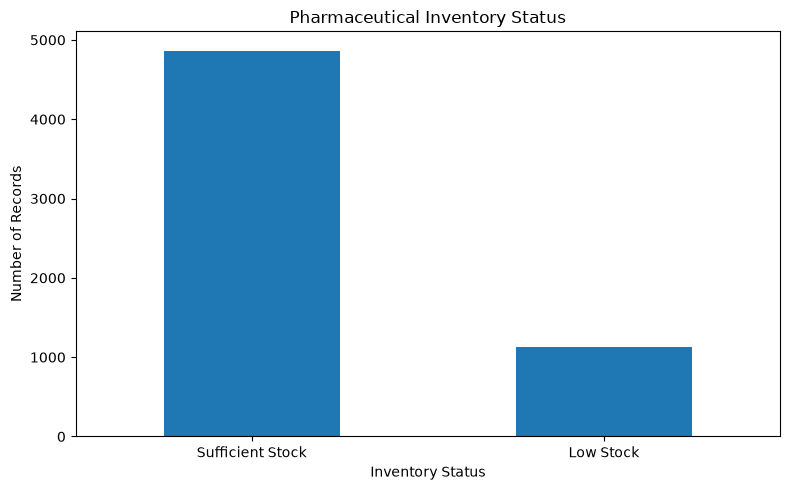

In [19]:
inventory_summary.plot(
    kind="bar",
    figsize=(8, 5),
    title="Pharmaceutical Inventory Status"
)

plt.xlabel("Inventory Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
import numpy as np

df_clean["inventory_status"] = np.select(
    [
        df_clean["stock_on_hand"].isna(),
        df_clean["stock_on_hand"] < df_clean["reorder_level"]
    ],
    [
        "Unknown Stock",
        "Low Stock"
    ],
    default="Sufficient Stock"
)

inventory_summary = df_clean["inventory_status"].value_counts()

display(inventory_summary)

inventory_status
Sufficient Stock    4845
Low Stock           1123
Unknown Stock         20
Name: count, dtype: int64

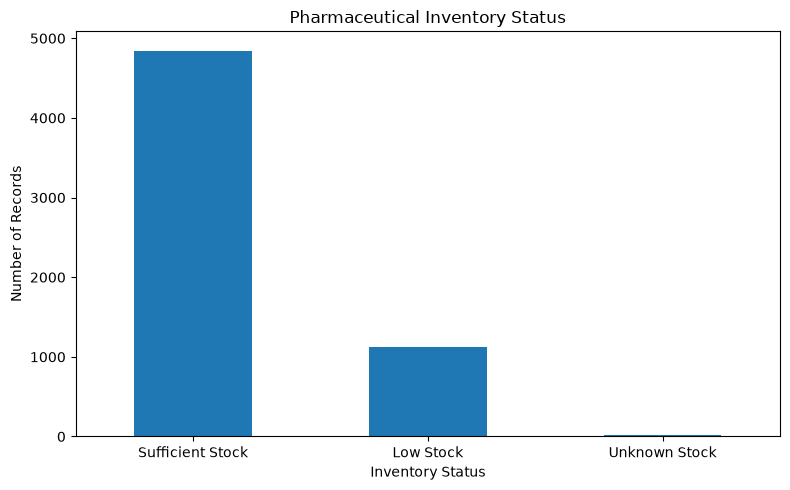

inventory_status
Sufficient Stock    4845
Low Stock           1123
Unknown Stock         20
Name: count, dtype: int64

In [22]:
import numpy as np
import matplotlib.pyplot as plt

df_clean["inventory_status"] = np.select(
    [
        df_clean["stock_on_hand"].isna(),
        df_clean["stock_on_hand"] < df_clean["reorder_level"]
    ],
    ["Unknown Stock", "Low Stock"],
    default="Sufficient Stock"
)

inventory_summary = df_clean["inventory_status"].value_counts()

inventory_summary.plot(kind="bar", figsize=(8, 5),
                       title="Pharmaceutical Inventory Status")

plt.xlabel("Inventory Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(inventory_summary)

In [23]:
df_clean["expiry_date"] = pd.to_datetime(
    df_clean["expiry_date"],
    errors="coerce"
)

print("Expiry date data type:",
      df_clean["expiry_date"].dtype)

print("Missing expiry dates:",
      df_clean["expiry_date"].isna().sum())

display(df_clean[["product_name", "expiry_date"]].head(10))

Expiry date data type: datetime64[us]
Missing expiry dates: 0


,product_name,expiry_date
0,Amoxicillin 250mg,2026-07-13
1,ORS Sachet,2028-11-12
2,Vitamin C 500mg,2028-03-31
3,ORS Sachet,2026-05-23
4,Vitamin C 500mg,2026-07-23
5,Atorvastatin 10mg,2027-07-22
6,Amlodipine 5mg,2027-04-11
7,Amlodipine 5mg,2027-06-29
8,Vitamin C 500mg,2027-10-26
9,Paracetamol 500mg,2027-02-09


In [24]:
today = pd.Timestamp.today().normalize()

df_clean["days_to_expiry"] = (
    df_clean["expiry_date"] - today
).dt.days

display(
    df_clean[
        ["product_name", "expiry_date", "days_to_expiry"]
    ].head(10)
)

,product_name,expiry_date,days_to_expiry
0,Amoxicillin 250mg,2026-07-13,-122
1,ORS Sachet,2028-11-12,731
2,Vitamin C 500mg,2028-03-31,505
3,ORS Sachet,2026-05-23,-173
4,Vitamin C 500mg,2026-07-23,-112
5,Atorvastatin 10mg,2027-07-22,252
6,Amlodipine 5mg,2027-04-11,150
7,Amlodipine 5mg,2027-06-29,229
8,Vitamin C 500mg,2027-10-26,348
9,Paracetamol 500mg,2027-02-09,89


In [25]:
df_clean["expiry_status"] = np.select(
    [
        df_clean["days_to_expiry"].isna(),
        df_clean["days_to_expiry"] < 0,
        df_clean["days_to_expiry"].between(0, 90)
    ],
    [
        "Unknown Expiry",
        "Expired",
        "Expiring Within 90 Days"
    ],
    default="Safe (Above 90 Days)"
)

expiry_summary = df_clean["expiry_status"].value_counts()

display(expiry_summary)

expiry_status
Safe (Above 90 Days)       3583
Expired                    1872
Expiring Within 90 Days     533
Name: count, dtype: int64

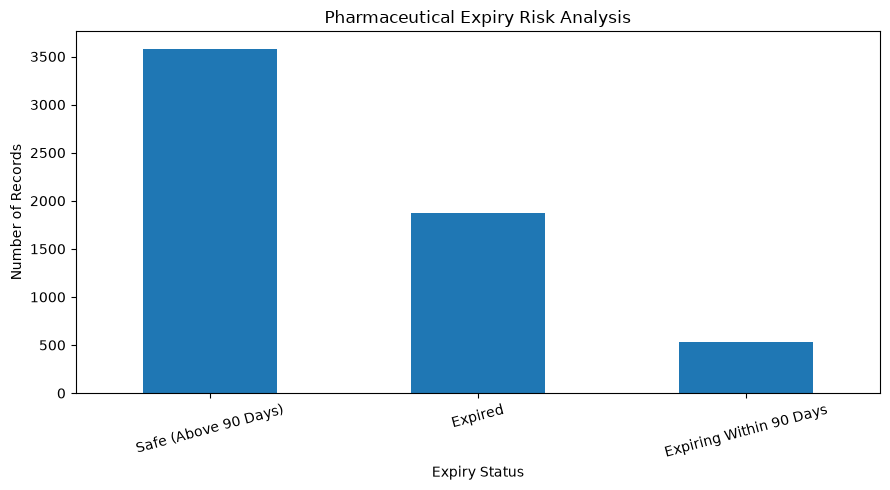

In [26]:
import matplotlib.pyplot as plt

expiry_summary = df_clean["expiry_status"].value_counts()

plt.figure(figsize=(9, 5))

expiry_summary.plot(kind="bar")

plt.title("Pharmaceutical Expiry Risk Analysis")
plt.xlabel("Expiry Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [27]:
expiry_percentage = (
    expiry_summary / expiry_summary.sum() * 100
)

display(expiry_percentage.round(2))

expiry_status
Safe (Above 90 Days)       59.84
Expired                    31.26
Expiring Within 90 Days     8.90
Name: count, dtype: float64

In [28]:
print("Quality Status Categories:")
display(df_clean["quality_status"].value_counts(dropna=False))

Quality Status Categories:


quality_status
Passed          5413
Under Review     425
Failed           150
Name: count, dtype: int64

In [29]:
quality_percentage = (
    df_clean["quality_status"]
    .value_counts(normalize=True, dropna=False) * 100
)

display(quality_percentage.round(2))

quality_status
Passed          90.40
Under Review     7.10
Failed           2.51
Name: proportion, dtype: float64

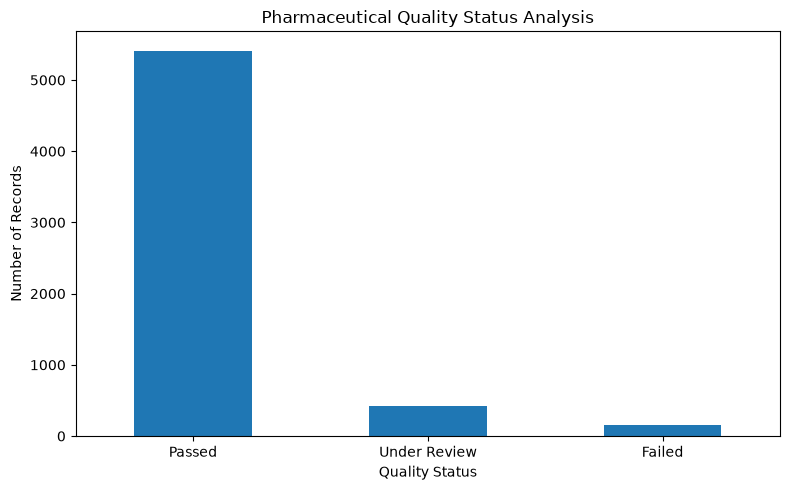

In [30]:
import matplotlib.pyplot as plt

quality_summary = df_clean["quality_status"].value_counts()

plt.figure(figsize=(8, 5))

quality_summary.plot(kind="bar")

plt.title("Pharmaceutical Quality Status Analysis")
plt.xlabel("Quality Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [31]:
quality_percentage = (
    quality_summary / quality_summary.sum() * 100
)

display(quality_percentage.round(2))

quality_status
Passed          90.40
Under Review     7.10
Failed           2.51
Name: count, dtype: float64

In [32]:
import pandas as pd

# Inventory report
inventory_report = (
    df_clean["inventory_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="records")
)
inventory_report["analysis"] = "Inventory"

# Expiry report
expiry_report = (
    df_clean["expiry_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="records")
)
expiry_report["analysis"] = "Expiry"

# Quality report
quality_report = (
    df_clean["quality_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="records")
)
quality_report["analysis"] = "Quality"

# Combine all reports
final_report = pd.concat(
    [inventory_report, expiry_report, quality_report],
    ignore_index=True
)

# Calculate percentages within each analysis
final_report["percentage"] = (
    final_report["records"]
    / final_report.groupby("analysis")["records"].transform("sum")
    * 100
)

display(final_report.round(2))

,status,records,analysis,percentage
0,Sufficient Stock,4845,Inventory,80.91
1,Low Stock,1123,Inventory,18.75
2,Unknown Stock,20,Inventory,0.33
3,Safe (Above 90 Days),3583,Expiry,59.84
4,Expired,1872,Expiry,31.26
5,Expiring Within 90 Days,533,Expiry,8.90
6,Passed,5413,Quality,90.40
7,Under Review,425,Quality,7.10
8,Failed,150,Quality,2.51


In [33]:
final_report.to_csv(
    "Pharmaceutical_Final_Analysis_Report.csv",
    index=False
)

print("Final analysis report saved successfully!")

Final analysis report saved successfully!


In [34]:
df_clean.to_csv(
    "Pharmaceutical_Cleaned_Data.csv",
    index=False
)

print("Cleaned pharmaceutical dataset exported!")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

Cleaned pharmaceutical dataset exported!
Rows: 5988
Columns: 22


In [35]:
import os

print("Current folder:", os.getcwd())
print("CSV file exists:",
      os.path.exists("Pharmaceutical_Cleaned_Data.csv"))

Current folder: c:\Users\ELCOT\Desktop\Pharmaceutical_Data_Analyst_Project
CSV file exists: True
